In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

Dataset Shape:
(1000, 9)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
None

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Values:
0


In [4]:
# Descriptive Statistics

numeric_columns = df.select_dtypes(include=np.number)

print("MEAN:")
print(numeric_columns.mean())

print("\nMEDIAN:")
print(numeric_columns.median())

print("\nMODE:")
print(numeric_columns.mode().iloc[0])

print("\nSTANDARD DEVIATION:")
print(numeric_columns.std())

MEAN:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [5]:
# Convert Date column

df['Date'] = pd.to_datetime(df['Date'])

print("Date column converted successfully!")

print(df['Date'].dtype)

Date column converted successfully!
datetime64[ns]


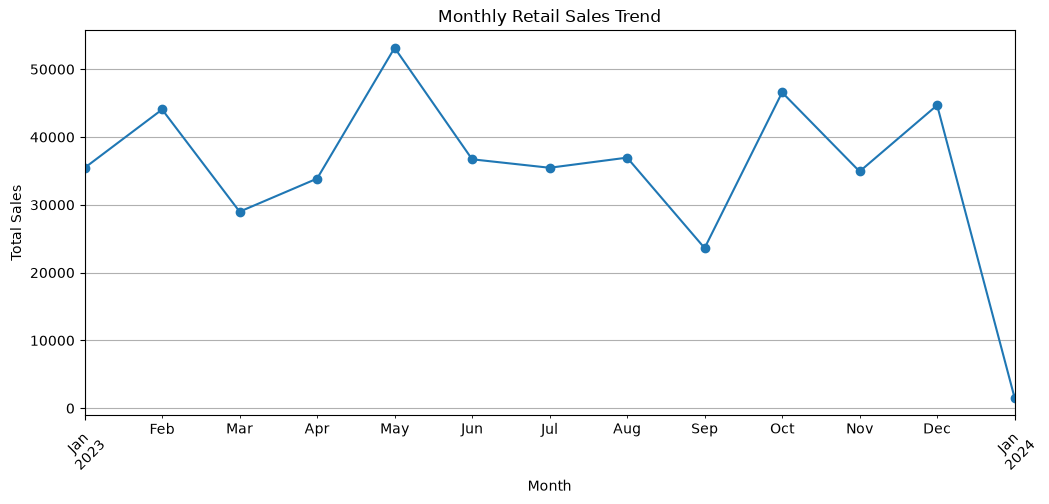

In [6]:
# Monthly Sales Analysis

df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Total Amount'].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid()
plt.show()

Observation:
The monthly sales chart helps identify changes in
sales performance over time. It highlights months
with higher and lower revenue.

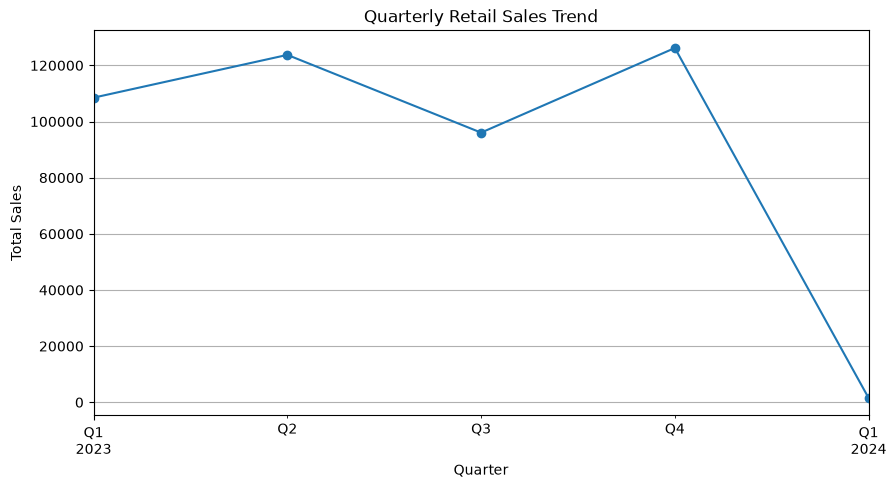

In [7]:
# Quarterly Sales Analysis

df['Quarter'] = df['Date'].dt.to_period('Q')

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind='line', marker='o')

plt.title('Quarterly Retail Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.grid()
plt.show()

Observation:
The quarterly sales chart shows how revenue changes
across different quarters. It helps identify the
strongest and weakest sales periods.

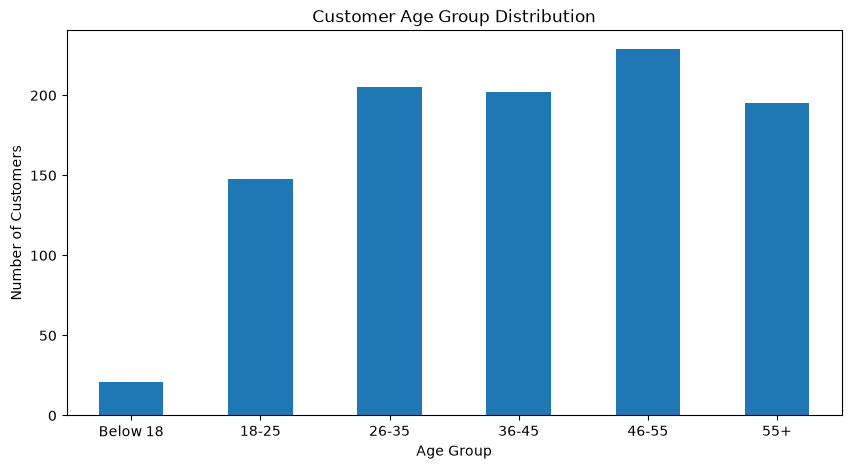

In [8]:
# Customer Age Group Analysis

df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=['Below 18', '18-25', '26-35', '36-45', '46-55', '55+']
)

age_distribution = df['Age Group'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

age_distribution.plot(kind='bar')

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')

plt.xticks(rotation=0)
plt.show()

Observation:
This chart shows the distribution of customers
across different age groups. It helps identify
which age groups contribute most to transactions.

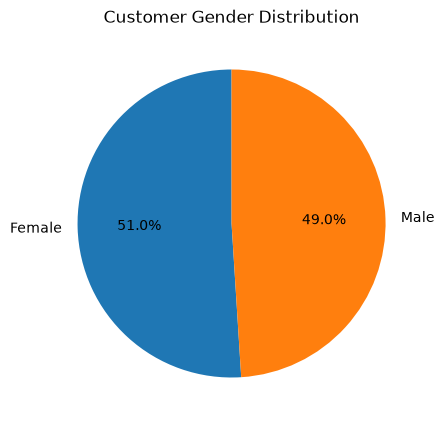

In [9]:
# Gender Distribution

gender_count = df['Gender'].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')

plt.show()

Observation:
The gender distribution chart shows the percentage
of male and female customers in the dataset.
It helps understand the customer demographic mix.

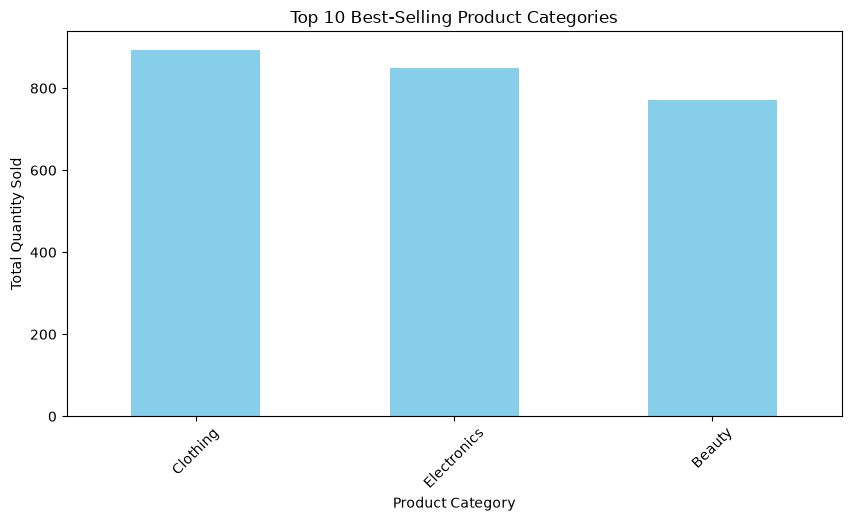

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


In [10]:
# Top 10 Best-Selling Products

top_products = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))

top_products.plot(kind='bar', color='skyblue')

plt.title('Top 10 Best-Selling Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.xticks(rotation=45)
plt.show()

print(top_products)

Observation:
This chart identifies the product categories with
the highest quantities sold. It helps businesses
understand which products are popular among customers.

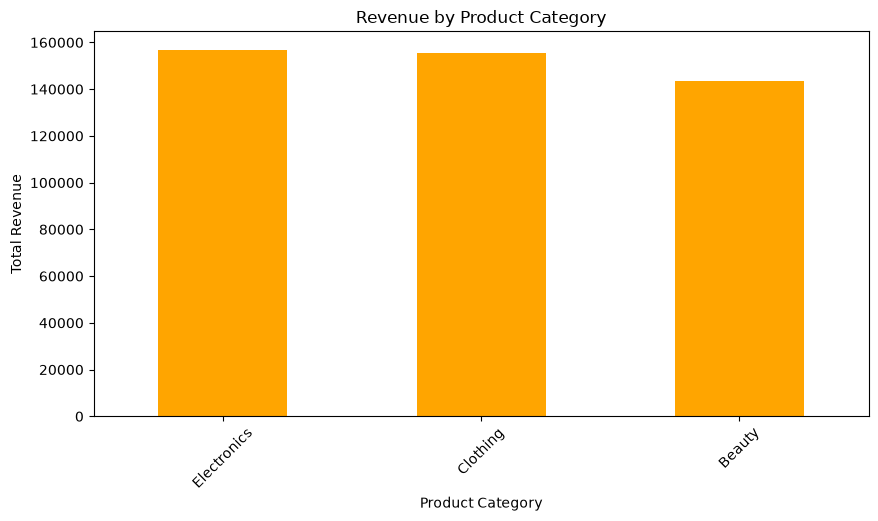

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [11]:
# Revenue by Product Category

category_revenue = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

category_revenue.plot(kind='bar', color='orange')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.show()

print(category_revenue)

Observation:
This chart compares the revenue generated by
different product categories. It helps identify
the categories contributing the most to total sales.

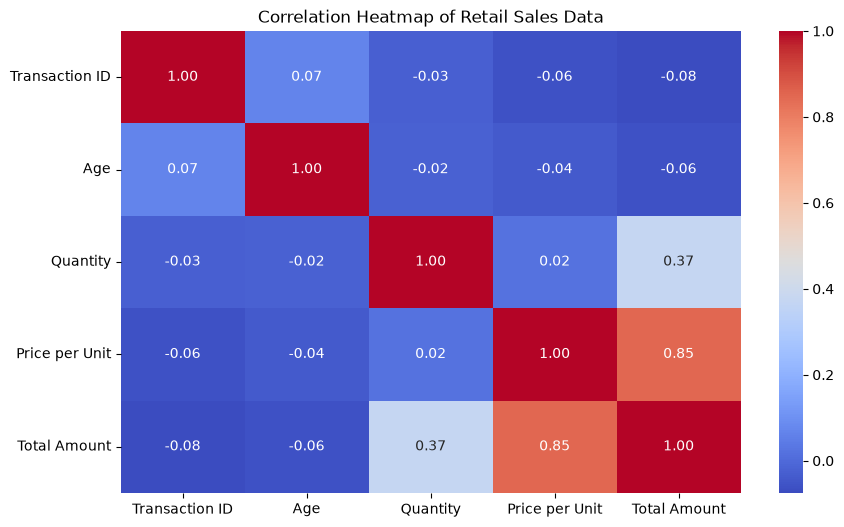

In [13]:
# Correlation Heatmap

plt.figure(figsize=(10, 6))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Retail Sales Data')

plt.show()

Observation:
The correlation heatmap shows the relationships
between numerical variables.

Positive correlation indicates that two variables
tend to increase together, while negative correlation
indicates that one tends to decrease as the other increases.

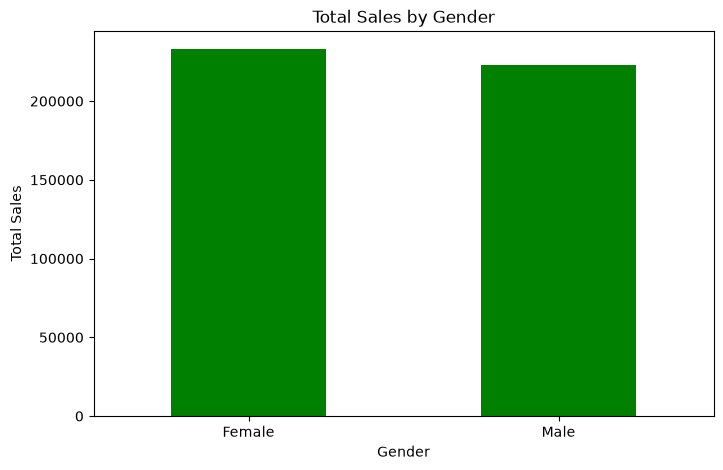

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [14]:
# Sales by Gender

gender_sales = df.groupby('Gender')['Total Amount'].sum()

plt.figure(figsize=(8, 5))

gender_sales.plot(kind='bar', color='green')

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

print(gender_sales)

Observation:
This chart compares total revenue generated by
male and female customers. It helps understand
customer purchasing patterns.